# Proyek Analisis Data: E-commerce-public-dataset
- **Nama:** Vlaura
- **Email:** vlauraagt@gmail.com
- **ID Dicoding:** DS009B6X1760

## Menentukan Pertanyaan Bisnis

**SMART Question** adalah sebuah framework untuk merumuskan pertanyaan secara terstruktur agar memeperoleh informasi yang mendalam.

* **Spesific (Spesifik)**
  * Pertanyaan harus jelas, fokus pada sebuah topik tertentu, dan tidak bermakna ganda. Hindari pertanyaan yang terlalu luas.
    * Salah: Bagaimana cara meningkatkan penjualan?
    * Benar: Faktor apa saja yang memengaruhi penurunan penjualan produk kategori elektronik di wilayah Jakarta selama kuartal terakhir?
* **Measurable (Terukur)**
  * Pertanyaan harus bisa dijawab dengan angka atau matrix yang konkret, harus tahu apa yang akan dihitung.
    * Salah: Apakah pelanggan senang dengan layanan kita?
    * Benar: Berapa skor rata-rata Customer Satisfaction untuk layanan purna jual bulan ini dibandingkan bulan lalu?
* **Action-Oriented (Berorientasi Aksi)**
  * Hasil dari pertanyaan harus bisa memberikan arahan untuk melakukan tindakan nyata. Jika pertanyaan terjawab, stakeholder harus tahu apa langkah selanjutnya.
    * Salah: Mengapa orang suka berbelanja?
    * Benar: Fitur apa pada aplikasi yang paling sering digunakan sebelum pengguna memutuskan untuk melakukan checkout?
* **Relevant (Relevan)**
  * Hasil dari pertanyaan harus sejalan dengan tujuan utama bisnis atau masalah yang sedang dihadapi.
    * Salah: Menanyakan tentang stok gudang saat masalah utamanya adalah efektivitas kampanye media sosial.
    * Benar: Apakah kampanye iklan di Instagram memberikan Return on Ad Spend (ROAS) yang lebih tinggi dibandingkan iklan di TikTok?
* **Time-bound (Terikat Waktu)**
  * Pertanyaan harus ada batasan waktu yang jelas agar analisis memiliki konteks yang tepat.
    * Salah: Berapa banyak pengguna baru kita?
    * Benar: Berapa tingkat pertumbuhan pengguna baru secara bulanan (Month-over-Month) sepanjang tahun 2025?

**Contoh pertanyaan bisnis yang memenuhi seluruh elemen SMART**

***"Faktor apa saja yang memengaruhi penurunan conversion rate pada pengguna aplikasi Android di wilayah Jabodetabek sebesar 5% selama periode Flash Sale Maret 2026?"***

Keterangan:

- **Specific**: Fokus pada "penurunan conversion rate" untuk "aplikasi Android" di "Jabodetabek". Bukan sekadar penjualan turun.
- **Measurable**: Ada angka konkret yang ingin dianalisis, yaitu penurunan sebesar "5%".
- **Action-Oriented**: Dengan mengetahui faktor penyebabnya misalnya bug pada versi Android tertentu atau kendala logistik di Jabodetabek, tim bisa langsung melakukan perbaikan teknis atau operasional.
- **Relevant**: Penurunan konversi saat Flash Sale adalah masalah kritis bagi bisnis retail/e-commerce.
- **Time-bound**: Dibatasi pada periode spesifik "Flash Sale Maret 2026".

- **Pertanyaan 1:** Bagaimana tren total pendapatan penjualan dan jumlah pesanan setiap bulan selama periode September 2016 hingga September 2018?
- **Pertanyaan 2:** Kategori produk apa saja yang menghasilkan total pendapatan dan jumlah penjualan tertinggi selama periode September 2016 hingga September 2018?
- **Pertanyaan 3:** Berapa persentase dan jumlah pesanan yang berhasil dikirim tepat waktu selama periode 4 September 2016 hingga 3 September 2018?

## Import Semua Packages/Library yang Digunakan

In [1]:
# Import library
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import zipfile
import os

## Data Wrangling

### Gathering Data

#### Load df ...

In [2]:
zip_path = '/content/E-commerce-public-dataset.zip'

with zipfile.ZipFile(zip_path, 'r') as zip_file:

    # Membaca dataset orders
    df_orders = pd.read_csv(
        zip_file.open('E-Commerce Public Dataset/orders_dataset.csv')
    )

    # Membaca dataset order_items
    df_order_items = pd.read_csv(
        zip_file.open('E-Commerce Public Dataset/order_items_dataset.csv')
    )

    # Membaca dataset products
    df_products = pd.read_csv(
        zip_file.open('E-Commerce Public Dataset/products_dataset.csv')
    )

    # Membaca dataset category translation
    df_translation = pd.read_csv(
        zip_file.open('E-Commerce Public Dataset/product_category_name_translation.csv')
    )

In [3]:
print("Orders Dataset:", df_orders.shape)
print("Order Items Dataset:", df_order_items.shape)
print("Products Dataset:", df_products.shape)
print("Category Translation Dataset:", df_translation.shape)

Orders Dataset: (99441, 8)
Order Items Dataset: (112650, 7)
Products Dataset: (32951, 9)
Category Translation Dataset: (71, 2)


In [4]:
# Dataset orders
df_orders = df_orders[[
    'order_id',
    'order_status',
    'order_purchase_timestamp',
    'order_delivered_customer_date',
    'order_estimated_delivery_date'
]]

# Dataset order_items
df_order_items = df_order_items[[
    'order_id',
    'order_item_id',
    'product_id',
    'price'
]]

# Dataset products
df_products = df_products[[
    'product_id',
    'product_category_name'
]]

# Dataset translation
df_translation = df_translation[[
    'product_category_name',
    'product_category_name_english'
]]

In [5]:
# Merge data
df = df_orders.merge(df_order_items, on='order_id', how='inner')
df = df.merge(df_products, on='product_id', how='left')
df = df.merge(df_translation, on='product_category_name', how='left')

In [6]:
display(df.head())

print("Jumlah baris dan kolom:", df.shape)
print("\nDaftar kolom:")
print(df.columns.tolist())

,order_id,order_status,order_purchase_timestamp,order_delivered_customer_date,order_estimated_delivery_date,order_item_id,product_id,price,product_category_name,product_category_name_english
0,e481f51cbdc54678b7cc49136f2d6af7,delivered,2017-10-02 10:56:33,2017-10-10 21:25:13,2017-10-18 00:00:00,1,87285b34884572647811a353c7ac498a,29.99,utilidades_domesticas,housewares
1,53cdb2fc8bc7dce0b6741e2150273451,delivered,2018-07-24 20:41:37,2018-08-07 15:27:45,2018-08-13 00:00:00,1,595fac2a385ac33a80bd5114aec74eb8,118.70,perfumaria,perfumery
2,47770eb9100c2d0c44946d9cf07ec65d,delivered,2018-08-08 08:38:49,2018-08-17 18:06:29,2018-09-04 00:00:00,1,aa4383b373c6aca5d8797843e5594415,159.90,automotivo,auto
3,949d5b44dbf5de918fe9c16f97b45f8a,delivered,2017-11-18 19:28:06,2017-12-02 00:28:42,2017-12-15 00:00:00,1,d0b61bfb1de832b15ba9d266ca96e5b0,45.00,pet_shop,pet_shop
4,ad21c59c0840e6cb83a9ceb5573f8159,delivered,2018-02-13 21:18:39,2018-02-16 18:17:02,2018-02-26 00:00:00,1,65266b2da20d04dbe00c5c2d3bb7859e,19.90,papelaria,stationery


Jumlah baris dan kolom: (112650, 10)

Daftar kolom:
['order_id', 'order_status', 'order_purchase_timestamp', 'order_delivered_customer_date', 'order_estimated_delivery_date', 'order_item_id', 'product_id', 'price', 'product_category_name', 'product_category_name_english']


**Insight:**
- Dataset yang digunakan terdiri dari empat sumber data, yaitu orders,
order_items, products, dan product_category_name_translation.
- Dataset orders menyediakan informasi pesanan, seperti status pesanan, tanggal pembelian, tanggal pengiriman aktual, dan estimasi pengiriman.
- Dataset order_items menyediakan informasi produk dalam setiap pesanan, termasuk ID produk dan harga.
- Dataset products menyediakan informasi kategori dari setiap produk melalui product_id.
- Dataset product_category_name_translation digunakan untuk menerjemahkan nama kategori produk dari bahasa Portugis ke bahasa Inggris agar lebih mudah dipahami.

### Assessing Data

#### Identifying data type

In [7]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 112650 entries, 0 to 112649
Data columns (total 10 columns):
 #   Column                         Non-Null Count   Dtype  
---  ------                         --------------   -----  
 0   order_id                       112650 non-null  object 
 1   order_status                   112650 non-null  object 
 2   order_purchase_timestamp       112650 non-null  object 
 3   order_delivered_customer_date  110196 non-null  object 
 4   order_estimated_delivery_date  112650 non-null  object 
 5   order_item_id                  112650 non-null  int64  
 6   product_id                     112650 non-null  object 
 7   price                          112650 non-null  float64
 8   product_category_name          111047 non-null  object 
 9   product_category_name_english  111023 non-null  object 
dtypes: float64(1), int64(1), object(8)
memory usage: 8.6+ MB


**Steps to Take:**
- Mengidentifikasi tipe data setiap kolom.
- Mengonversi kolom tanggal dari object menjadi datetime.
- Memastikan kolom price bertipe numerik.

**Insight:**
- Dataset memiliki 112.650 baris dan 10 kolom.
- Terdapat 3 kolom tanggal yang masih bertipe object dan perlu dikonversi menjadi datetime.
- Kolom price sudah bertipe numerik dan siap digunakan untuk analisis pendapatan.

#### Identifying missing value

In [8]:
missing_values = pd.DataFrame({
    'Missing Values': df.isnull().sum(),
    'Percentage (%)': (df.isnull().mean() * 100).round(2)
})

display(missing_values[missing_values['Missing Values'] > 0])

,Missing Values,Percentage (%)
order_delivered_customer_date,2454,2.18
product_category_name,1603,1.42
product_category_name_english,1627,1.44


**Steps to Take:**
- Mengidentifikasi jumlah dan persentase nilai kosong pada setiap kolom.
- Memeriksa penyebab nilai kosong sebelum menentukan penanganannya.

**Insight:**
- order_delivered_customer_date memiliki 2.454 missing values (2,18%), kemungkinan pesanan belum berhasil dikirim.
- product_category_name memiliki 1.603 missing values (1,42%).
- product_category_name_english memiliki 1.627 missing values (1,44%).
- Missing values pada tanggal pengiriman tidak perlu langsung dihapus karena diperlukan untuk analisis status pengiriman.

#### Identifying Duplicate Data

In [9]:
print("Duplikasi seluruh baris:", df.duplicated().sum())

print("Duplikasi order_id dan order_item_id:",
      df.duplicated(subset=['order_id', 'order_item_id']).sum())

Duplikasi seluruh baris: 0
Duplikasi order_id dan order_item_id: 0


**Steps to Take:**
- Memeriksa duplikasi seluruh baris dan kombinasi order_id dengan order_item_id.
- Memastikan tidak ada data transaksi yang tercatat ganda.

**Insight :**

- Tidak ditemukan duplikasi pada seluruh baris maupun kombinasi order_id dan order_item_id.
- Dataset tidak memerlukan penghapusan data duplikat.

#### Identifying Data Period

In [14]:
print("Tanggal paling awal:", df['order_purchase_timestamp'].min())
print("Tanggal paling akhir:", df['order_purchase_timestamp'].max())

Tanggal paling awal: 2016-09-04 21:15:19
Tanggal paling akhir: 2018-09-03 09:06:57


**Steps to Take:**
- Memeriksa tanggal transaksi paling awal dan paling akhir.
- Memastikan rentang waktu sesuai dengan periode analisis.

**Insight :**

- Data transaksi mencakup periode 4 September 2016 hingga 3 September 2018.

### Cleaning Data

#### Fixing Data Types

In [10]:
date_columns = [
    'order_purchase_timestamp',
    'order_delivered_customer_date',
    'order_estimated_delivery_date'
]

for col in date_columns:
    df[col] = pd.to_datetime(df[col])

**Insight:** Kolom tanggal berhasil dikonversi menjadi tipe datetime.
Data siap digunakan untuk analisis tren bulanan dan durasi pengiriman.

#### Handling Missing Values

In [11]:
# Mengisi kategori produk yang kosong
df['product_category_name_english'] = df['product_category_name_english'].fillna('unknown')

**Insight:**
- Missing values pada kategori produk ditandai sebagai unknown.
- Missing values tanggal pengiriman dipertahankan karena dapat menunjukkan pesanan yang belum terkirim.

## Exploratory Data Analysis (EDA)

### Explore Tren Penjualan Bulanan

In [12]:
monthly_sales = df.groupby(
    df['order_purchase_timestamp'].dt.to_period('M')
).agg(
    total_revenue=('price', 'sum'),
    total_orders=('order_id', 'nunique')
).reset_index()

monthly_sales['month'] = monthly_sales['order_purchase_timestamp'].astype(str)

display(monthly_sales)

,order_purchase_timestamp,total_revenue,total_orders,month
0,2016-09,267.36,3,2016-09
1,2016-10,49507.66,308,2016-10
2,2016-12,10.90,1,2016-12
3,2017-01,120312.87,789,2017-01
4,2017-02,247303.02,1733,2017-02
5,2017-03,374344.30,2641,2017-03
6,2017-04,359927.23,2391,2017-04
7,2017-05,506071.14,3660,2017-05
8,2017-06,433038.60,3217,2017-06
9,2017-07,498031.48,3969,2017-07


**Insight:**
- Pendapatan dan jumlah pesanan menunjukkan tren meningkat dari tahun 2017 hingga 2018.
- November 2017 mencatat pendapatan tertinggi sebesar 1.010.271,37 dengan 7.451 pesanan.
- Pada April-Mei 2018, pendapatan relatif stabil di sekitar 996 ribu, kemudian mengalami penurunan pada Juni 2018.

### Explore Product Category Performance

In [16]:
category_sales = df[df['product_category_name_english'] != 'unknown'].groupby(
    'product_category_name_english'
).agg(
    total_revenue=('price', 'sum'),
    total_sales=('product_id', 'count')
).reset_index()

display(category_sales.sort_values('total_revenue', ascending=False).head(10))

,product_category_name_english,total_revenue,total_sales
43,health_beauty,1258681.34,9670
70,watches_gifts,1205005.68,5991
7,bed_bath_table,1036988.68,11115
65,sports_leisure,988048.97,8641
15,computers_accessories,911954.32,7827
39,furniture_decor,729762.49,8334
20,cool_stuff,635290.85,3796
49,housewares,632248.66,6964
5,auto,592720.11,4235
42,garden_tools,485256.46,4347


**Insight:**
- Kategori health_beauty menghasilkan pendapatan tertinggi sebesar 1.258.681,34, dengan 9.670 produk terjual.
- Kategori bed_bath_table memiliki jumlah penjualan tertinggi sebanyak 11.115 produk, tetapi berada di posisi ketiga berdasarkan pendapatan.
- Kategori watches_gifts menempati posisi kedua berdasarkan pendapatan, yaitu 1.205.005,68, meskipun jumlah penjualannya lebih rendah dibandingkan beberapa kategori lainnya.

### Explore Delivery Performance

In [27]:
# Menghitung jumlah dan persentase status pengiriman
delivery_explore = df_delivery['delivery_status'].value_counts().reset_index()

delivery_explore.columns = ['Status Pengiriman', 'Jumlah Pesanan']

delivery_explore['Persentase (%)'] = (
    delivery_explore['Jumlah Pesanan'] / delivery_explore['Jumlah Pesanan'].sum() * 100
)

display(delivery_explore)

,Status Pengiriman,Jumlah Pesanan,Persentase (%)
0,Tepat Waktu,88644,91.887633
1,Terlambat,7826,8.112367


**Insight:**
- Sebanyak 88.644 pesanan (91,89%) berhasil dikirim tepat waktu.
- Sebanyak 7.826 pesanan (8,11%) mengalami keterlambatan pengiriman.
- Mayoritas pesanan berhasil diterima pelanggan sesuai atau sebelum tanggal estimasi pengiriman.

## Visualization & Explanatory Analysis

### Pertanyaan 1: Bagaimana tren total pendapatan penjualan dan jumlah pesanan setiap bulan selama periode September 2016 hingga September 2018?

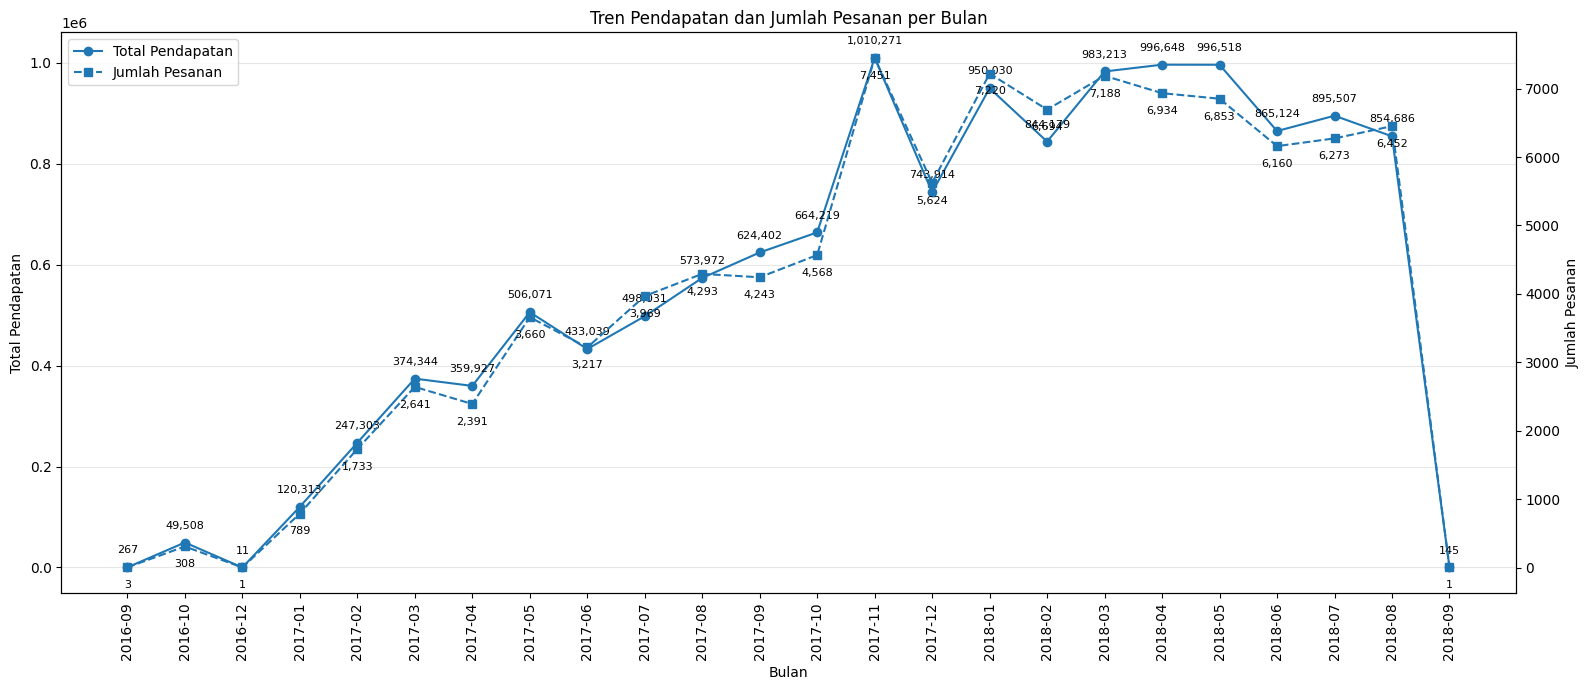

In [35]:
# Menghitung pendapatan dan jumlah pesanan per bulan
monthly_sales = df.groupby(
    df['order_purchase_timestamp'].dt.to_period('M')
).agg(
    total_revenue=('price', 'sum'),
    total_orders=('order_id', 'nunique')
).reset_index()

monthly_sales['month'] = monthly_sales[
    'order_purchase_timestamp'
].astype(str)

# Membuat visualisasi dengan dua sumbu Y
fig, ax1 = plt.subplots(figsize=(16, 7))

# Grafik total pendapatan
ax1.plot(
    monthly_sales['month'],
    monthly_sales['total_revenue'],
    marker='o',
    label='Total Pendapatan'
)

ax1.set_xlabel('Bulan')
ax1.set_ylabel('Total Pendapatan')
ax1.tick_params(axis='x', rotation=90)
ax1.grid(axis='y', alpha=0.3)

# Menampilkan angka pendapatan
for x, y in zip(monthly_sales['month'], monthly_sales['total_revenue']):
    ax1.annotate(
        f'{y:,.0f}',
        (x, y),
        textcoords='offset points',
        xytext=(0, 10),
        ha='center',
        fontsize=8
    )

# Grafik jumlah pesanan
ax2 = ax1.twinx()

ax2.plot(
    monthly_sales['month'],
    monthly_sales['total_orders'],
    marker='s',
    linestyle='--',
    label='Jumlah Pesanan'
)

ax2.set_ylabel('Jumlah Pesanan')

# Menampilkan angka jumlah pesanan
for x, y in zip(monthly_sales['month'], monthly_sales['total_orders']):
    ax2.annotate(
        f'{y:,}',
        (x, y),
        textcoords='offset points',
        xytext=(0, -15),
        ha='center',
        fontsize=8
    )

# Menggabungkan legenda
lines1, labels1 = ax1.get_legend_handles_labels()
lines2, labels2 = ax2.get_legend_handles_labels()

ax1.legend(lines1 + lines2, labels1 + labels2, loc='upper left')

plt.title('Tren Pendapatan dan Jumlah Pesanan per Bulan')
plt.tight_layout()
plt.show()

**Insight:**
- Pendapatan dan jumlah pesanan menunjukkan tren peningkatan secara umum dari tahun 2017 hingga 2018.   
- Puncak pendapatan tertinggi tercatat pada November 2017 sebesar 1.010.271 dengan total 7.451 pesanan.   
- Pada periode April hingga Mei 2018, pendapatan stabil di kisaran 996 ribu sebelum mengalami penurunan pada Juni 2018.

### Pertanyaan 2: Kategori produk apa saja yang menghasilkan total pendapatan dan jumlah penjualan tertinggi selama periode September 2016 hingga September 2018?

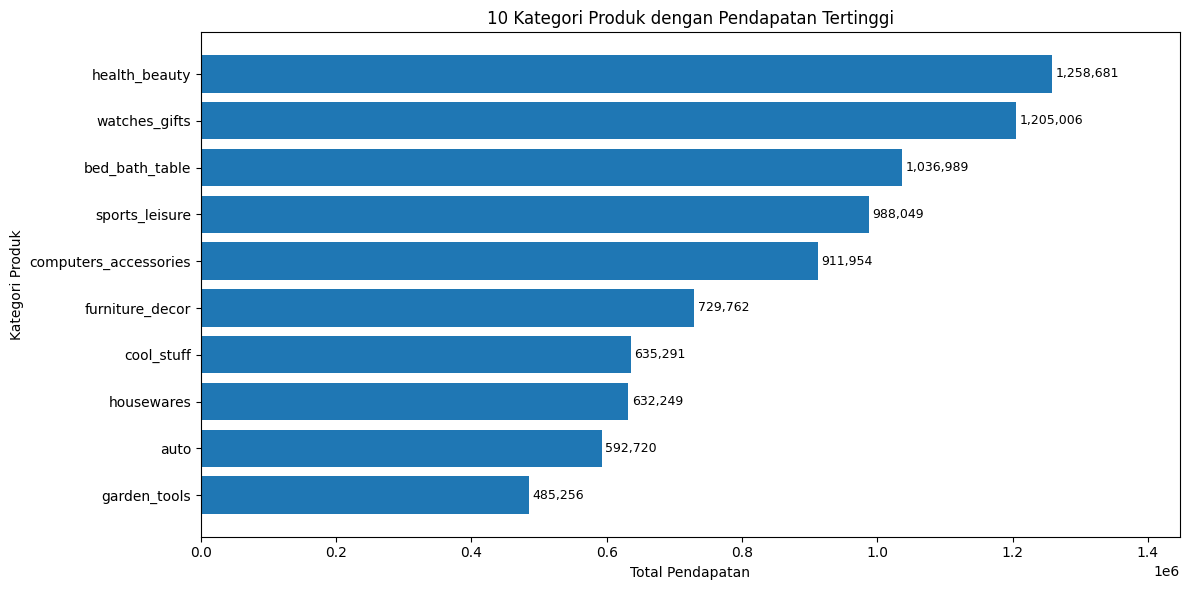

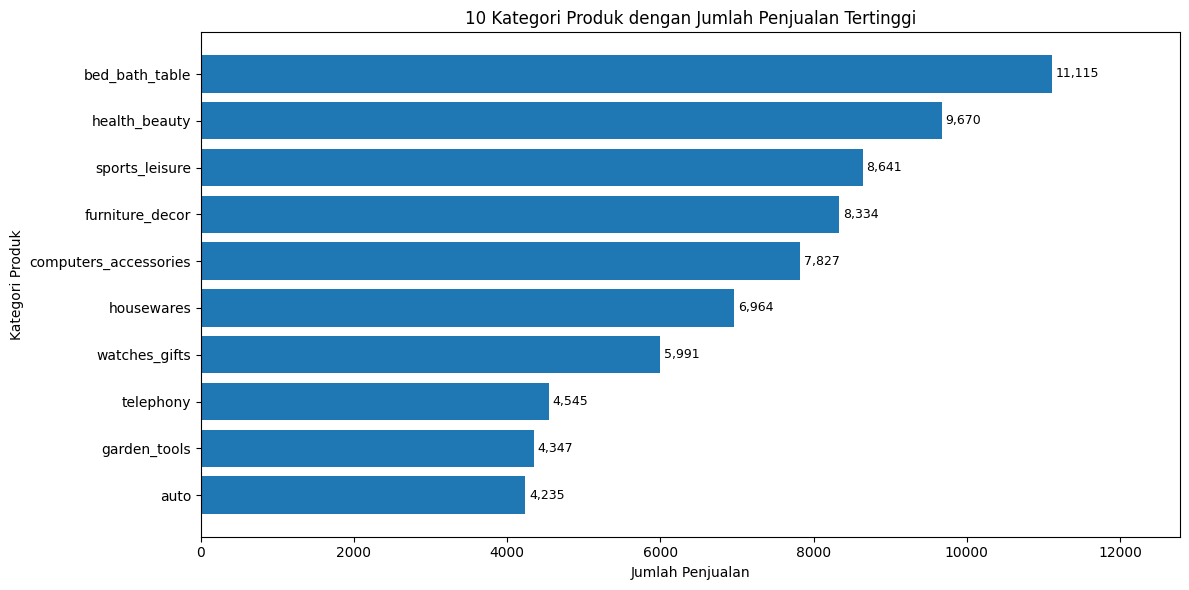

In [36]:
# Menghitung pendapatan dan jumlah penjualan per kategori
category_sales = df[
    df['product_category_name_english'] != 'unknown'
].groupby('product_category_name_english').agg(
    total_revenue=('price', 'sum'),
    total_sales=('product_id', 'count')
).reset_index()

# Mengambil 10 kategori dengan pendapatan tertinggi
top_revenue = category_sales.nlargest(10, 'total_revenue')

# Mengambil 10 kategori dengan jumlah penjualan tertinggi
top_sales = category_sales.nlargest(10, 'total_sales')


# Visualisasi pendapatan
plt.figure(figsize=(12, 6))

bars = plt.barh(
    top_revenue['product_category_name_english'],
    top_revenue['total_revenue']
)

plt.title('10 Kategori Produk dengan Pendapatan Tertinggi')
plt.xlabel('Total Pendapatan')
plt.ylabel('Kategori Produk')
plt.gca().invert_yaxis()

# Menampilkan angka pendapatan
for bar in bars:
    value = bar.get_width()
    plt.text(
        value + 5000,
        bar.get_y() + bar.get_height() / 2,
        f'{value:,.0f}',
        va='center',
        fontsize=9
    )

plt.xlim(0, top_revenue['total_revenue'].max() * 1.15)
plt.tight_layout()
plt.show()


# Visualisasi jumlah penjualan
plt.figure(figsize=(12, 6))

bars = plt.barh(
    top_sales['product_category_name_english'],
    top_sales['total_sales']
)

plt.title('10 Kategori Produk dengan Jumlah Penjualan Tertinggi')
plt.xlabel('Jumlah Penjualan')
plt.ylabel('Kategori Produk')
plt.gca().invert_yaxis()

# Menampilkan angka jumlah penjualan
for bar in bars:
    value = bar.get_width()
    plt.text(
        value + 50,
        bar.get_y() + bar.get_height() / 2,
        f'{value:,.0f}',
        va='center',
        fontsize=9
    )

plt.xlim(0, top_sales['total_sales'].max() * 1.15)
plt.tight_layout()
plt.show()

**Insight:**
- Kategori health_beauty menghasilkan total pendapatan tertinggi yaitu sebesar 1.258.681 dengan 9.670 produk terjual.   
- Kategori bed_bath_table mencatatkan jumlah penjualan terbanyak dengan 11.115 produk, namun berada di posisi ketiga dalam hal total pendapatan.
- Kategori watches_gifts menempati posisi kedua dalam total pendapatan (1.205.006) meskipun jumlah unit penjualannya lebih rendah dibanding beberapa kategori lain.

### Pertanyaan 3: Berapa persentase dan jumlah pesanan yang berhasil dikirim tepat waktu selama periode 4 September 2016 hingga 3 September 2018?

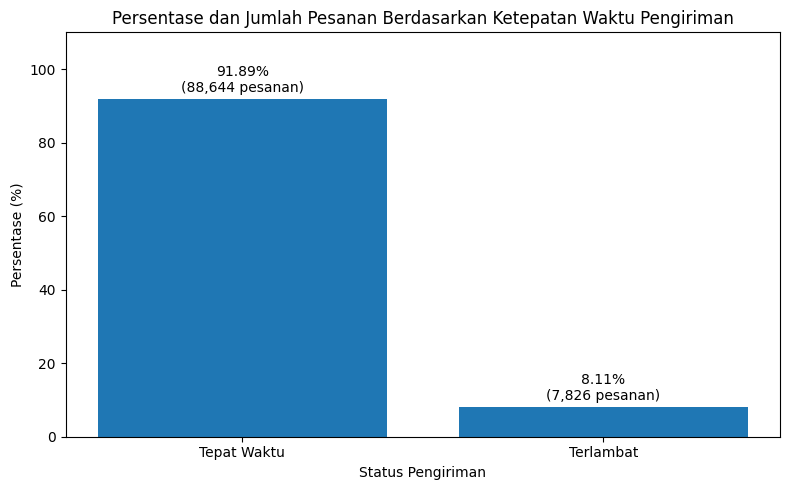

In [37]:
# Menghitung persentase dan jumlah pesanan berdasarkan status pengiriman
delivery_summary = df_delivery['delivery_status'].value_counts()

delivery_percentage = (
    delivery_summary / delivery_summary.sum() * 100
)

plt.figure(figsize=(8, 5))

bars = plt.bar(
    delivery_percentage.index,
    delivery_percentage.values
)

plt.title('Persentase dan Jumlah Pesanan Berdasarkan Ketepatan Waktu Pengiriman')
plt.xlabel('Status Pengiriman')
plt.ylabel('Persentase (%)')
plt.ylim(0, 110)

# Menampilkan persentase dan jumlah pesanan
for i, bar in enumerate(bars):
    percentage = delivery_percentage.iloc[i]
    total_orders = delivery_summary.iloc[i]

    plt.text(
        bar.get_x() + bar.get_width() / 2,
        bar.get_height() + 1,
        f'{percentage:.2f}%\n({total_orders:,} pesanan)',
        ha='center',
        va='bottom',
        fontsize=10
    )

plt.tight_layout()
plt.show()

**Insight:**
- Mayoritas pesanan, yakni sebanyak 88.644 pesanan (91,89%), berhasil dikirimkan kepada pelanggan secara tepat waktu.   
- Terdapat 7.826 pesanan (8,11%) yang mengalami keterlambatan dari estimasi waktu pengiriman.

## Analisis Lanjutan (Opsional)

### Customer Segmentation Using RFM Analysis

In [28]:
zip_path = '/content/E-commerce-public-dataset.zip'

with zipfile.ZipFile(zip_path, 'r') as zip_file:
    orders = pd.read_csv(
        zip_file.open('E-Commerce Public Dataset/orders_dataset.csv')
    )
    customers = pd.read_csv(
        zip_file.open('E-Commerce Public Dataset/customers_dataset.csv')
    )
    order_items = pd.read_csv(
        zip_file.open('E-Commerce Public Dataset/order_items_dataset.csv')
    )

# Menggabungkan data
rfm_df = orders.merge(
    customers[['customer_id', 'customer_unique_id']],
    on='customer_id',
    how='left'
)

rfm_df = rfm_df.merge(
    order_items[['order_id', 'price']],
    on='order_id',
    how='inner'
)

# Mengubah format tanggal
rfm_df['order_purchase_timestamp'] = pd.to_datetime(
    rfm_df['order_purchase_timestamp']
)

# Mengambil pesanan yang berhasil dikirim
rfm_df = rfm_df[rfm_df['order_status'] == 'delivered'].copy()

In [29]:
# Menentukan tanggal acuan
snapshot_date = (
    rfm_df['order_purchase_timestamp'].max() + pd.Timedelta(days=1)
)

# Menghitung Recency, Frequency, dan Monetary
rfm = rfm_df.groupby('customer_unique_id').agg(
    Recency=('order_purchase_timestamp',
             lambda x: (snapshot_date - x.max()).days),
    Frequency=('order_id', 'nunique'),
    Monetary=('price', 'sum')
).reset_index()

display(rfm.head())

,customer_unique_id,Recency,Frequency,Monetary
0,0000366f3b9a7992bf8c76cfdf3221e2,112,1,129.90
1,0000b849f77a49e4a4ce2b2a4ca5be3f,115,1,18.90
2,0000f46a3911fa3c0805444483337064,537,1,69.00
3,0000f6ccb0745a6a4b88665a16c9f078,321,1,25.99
4,0004aac84e0df4da2b147fca70cf8255,288,1,180.00


In [31]:
# Skor Recency
rfm['R_Score'] = pd.qcut(
    rfm['Recency'].rank(method='first'),
    4, labels=[4, 3, 2, 1]
).astype(int)

# Skor Frequency berdasarkan jumlah transaksi
rfm['F_Score'] = pd.cut(
    rfm['Frequency'],
    bins=[0, 1, 2, float('inf')],
    labels=[1, 2, 4]
).astype(int)

# Skor Monetary
rfm['M_Score'] = pd.qcut(
    rfm['Monetary'].rank(method='first'),
    4, labels=[1, 2, 3, 4]
).astype(int)

# Menggabungkan skor
rfm['RFM_Score'] = (
    rfm['R_Score'].astype(str) +
    rfm['F_Score'].astype(str) +
    rfm['M_Score'].astype(str)
)

display(rfm.head())

,customer_unique_id,Recency,Frequency,Monetary,R_Score,F_Score,M_Score,RFM_Score
0,0000366f3b9a7992bf8c76cfdf3221e2,112,1,129.90,4,1,3,413
1,0000b849f77a49e4a4ce2b2a4ca5be3f,115,1,18.90,3,1,1,311
2,0000f46a3911fa3c0805444483337064,537,1,69.00,1,1,2,112
3,0000f6ccb0745a6a4b88665a16c9f078,321,1,25.99,2,1,1,211
4,0004aac84e0df4da2b147fca70cf8255,288,1,180.00,2,1,4,214


In [32]:
def segment_customer(row):
    r = row['R_Score']
    f = row['F_Score']
    m = row['M_Score']

    if r >= 3 and f >= 3 and m >= 3:
        return 'Champions'
    elif f >= 3 and m >= 3:
        return 'Loyal Customers'
    elif r >= 3 and f <= 2:
        return 'Potential Loyalists'
    elif r <= 2 and f >= 2:
        return 'At Risk'
    else:
        return 'Others'

rfm['Customer_Segment'] = rfm.apply(
    segment_customer, axis=1
)

display(rfm.head())

,customer_unique_id,Recency,Frequency,Monetary,R_Score,F_Score,M_Score,RFM_Score,Customer_Segment
0,0000366f3b9a7992bf8c76cfdf3221e2,112,1,129.90,4,1,3,413,Potential Loyalists
1,0000b849f77a49e4a4ce2b2a4ca5be3f,115,1,18.90,3,1,1,311,Potential Loyalists
2,0000f46a3911fa3c0805444483337064,537,1,69.00,1,1,2,112,Others
3,0000f6ccb0745a6a4b88665a16c9f078,321,1,25.99,2,1,1,211,Others
4,0004aac84e0df4da2b147fca70cf8255,288,1,180.00,2,1,4,214,Others


In [33]:
segment_summary = rfm.groupby(
    'Customer_Segment', observed=True
).agg(
    total_customers=('customer_unique_id', 'count'),
    total_revenue=('Monetary', 'sum')
).reset_index()

segment_summary['percentage'] = (
    segment_summary['total_customers'] /
    segment_summary['total_customers'].sum() * 100
)

display(segment_summary)

,Customer_Segment,total_customers,total_revenue,percentage
0,At Risk,1181,288366.09,1.265023
1,Champions,136,63987.87,0.145676
2,Loyal Customers,77,32259.08,0.082478
3,Others,45427,6255840.22,48.658926
4,Potential Loyalists,46537,6581044.85,49.847897


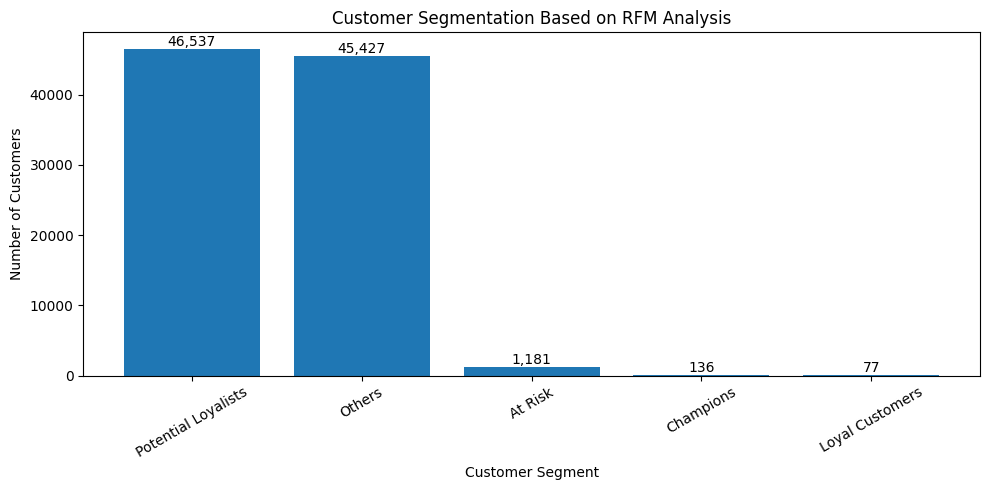

In [34]:
import matplotlib.pyplot as plt

segment_count = rfm['Customer_Segment'].value_counts()

plt.figure(figsize=(10, 5))
plt.bar(segment_count.index, segment_count.values)

plt.title('Customer Segmentation Based on RFM Analysis')
plt.xlabel('Customer Segment')
plt.ylabel('Number of Customers')
plt.xticks(rotation=30)

for i, value in enumerate(segment_count.values):
    plt.text(i, value, f'{value:,}', ha='center', va='bottom')

plt.tight_layout()
plt.show()

**Insight:**
Berdasarkan hasil RFM Analysis, diperoleh lima segmen pelanggan dengan karakteristik sebagai berikut:

- Potential Loyalists (49,85%): Mendominasi dengan 46.537 pelanggan. Kelompok ini merupakan pelanggan yang relatif baru melakukan pembelian, tetapi frekuensi transaksinya masih rendah.
- Others (48,66%): Terdiri dari 45.427 pelanggan yang belum memenuhi kriteria segmen lainnya.
- At Risk (1,27%): Sebanyak 1.181 pelanggan yang sudah cukup lama tidak melakukan pembelian, meskipun sebelumnya memiliki frekuensi transaksi relatif tinggi.
- Champions (0,15%): Sebanyak 136 pelanggan yang baru melakukan pembelian, sering bertransaksi, dan memiliki nilai pembelian tinggi.
- Loyal Customers (0,08%): Sebanyak 77 pelanggan dengan frekuensi transaksi dan nilai pembelian yang tinggi.

## Conclusion & Recommendation

- **Conclusion pertanyaan 1:** Bagaimana tren total pendapatan penjualan dan jumlah pesanan setiap bulan selama periode September 2016 hingga September 2018?

Total pendapatan dan jumlah pesanan menunjukkan tren peningkatan dari tahun 2017 hingga 2018. Pendapatan tertinggi terjadi pada November 2017 sebesar 1.010.271 dengan 7.451 pesanan. Secara umum, performa penjualan mengalami pertumbuhan meskipun terdapat fluktuasi pada beberapa bulan.

- **Conclusion pertanyaan 2:** Kategori produk apa saja yang menghasilkan total pendapatan dan jumlah penjualan tertinggi selama periode September 2016 hingga September 2018?

Kategori health_beauty menghasilkan pendapatan tertinggi sebesar 1.258.681 dengan 9.670 produk terjual. Sementara itu, kategori bed_bath_table memiliki jumlah penjualan tertinggi sebanyak 11.115 produk dengan pendapatan sebesar 1.036.988.


- **Conclusion pertanyaan 3:** Berapa persentase dan jumlah pesanan yang berhasil dikirim tepat waktu selama periode 4 September 2016 hingga 3 September 2018?

Sebanyak 88.644 pesanan (91,89%) berhasil dikirim tepat waktu, sedangkan 7.826 pesanan (8,11%) mengalami keterlambatan. Hal ini menunjukkan bahwa sebagian besar pesanan berhasil diterima pelanggan sesuai atau sebelum tanggal estimasi pengiriman.

**Rekomendasi Action Item:**
- Mempertahankan dan meningkatkan strategi pemasaran kategori health_beauty untuk mengoptimalkan pendapatan.

- Memastikan ketersediaan stok kategori bed_bath_table karena memiliki jumlah penjualan tertinggi.

- Mengevaluasi proses pengiriman dan kinerja mitra logistik untuk mengurangi keterlambatan pesanan.

- Memberikan promosi pembelian berikutnya kepada segmen Potential Loyalists untuk mendorong transaksi berulang.

- Memberikan program loyalitas dan penawaran eksklusif kepada segmen Champions dan Loyal Customers.

- Melakukan kampanye reaktivasi kepada segmen At Risk agar pelanggan kembali melakukan pembelian.